# Лабораторная работа №3. Оптимизация гиперпараметров

Цель: подобрать параметры дерева решений из второй лабораторной, сравнить Grid Search и Random Search и посмотреть, как меняется качество.

Данные: [Titanic Dataset, Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset). Файл Titanic-Dataset.csv лежит рядом с ноутбуком. В JupyterLite нужно загрузить оба файла в одну папку. Основная метрика — F1 для выживших, больше — лучше.

## 1. Импорт библиотек

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV, ParameterGrid, RandomizedSearchCV, StratifiedKFold,
    cross_validate, train_test_split, validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

## 2. Данные и разбиение

Использую те же семь признаков и разбиение, что во второй лабораторной. 80% строк идут в train, 20% — в test, доля классов сохраняется. Имена, ID, билеты и каюты в признаки не входят.

Этот локальный test уже оценивался во второй работе. Поэтому итог здесь — повторная проверка на прежней выборке, а не новый независимый эксперимент. В этой работе параметры выбираю только по train и CV, разбиение не меняю.

In [2]:
filename = 'Titanic-Dataset.csv'
data_path = next((p for p in (Path(filename), Path('hyperparameters') / filename) if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Загрузите Titanic-Dataset.csv в одну папку с lab03.ipynb.')
data = pd.read_csv(data_path)
numeric = ['Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Pclass', 'Sex', 'Embarked']
X = data[numeric + categorical].copy()
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
print(f'Всего: {len(data)}; train: {len(X_train)}; test: {len(X_test)}')
print(f'Доля выживших в train: {y_train.mean():.1%}')
display(X_train.isna().sum().to_frame('Пропуски в train'))

prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), categorical),
])
baseline = Pipeline([
    ('prep', prep),
    ('model', DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=SEED)),
])

Всего: 891; train: 712; test: 179
Доля выживших в train: 38.3%


,Пропуски в train
Age,137
SibSp,0
Parch,0
Fare,0
Pclass,0
Sex,0
Embarked,2


## 3. Исходная модель и кросс-валидация

Baseline этой работы — дерево из лабы 2: max_depth=5, min_samples_leaf=5, остальные параметры по умолчанию. Это уже обучаемая модель, а не Dummy.

Пропуски заполняются медианой или самой частой категорией, категории кодируются one-hot. Все шаги находятся в Pipeline и обучаются заново внутри каждого фолда. Дереву масштабирование не требуется.

Возьму пять стратифицированных фолдов: проверка меньше зависит от одной случайной части данных, а время остаётся небольшим. Во всех экспериментах фолды одинаковые. Одно разбиение может случайно дать лёгкую проверку. Если постоянно выбирать параметры по test, мы подстроимся под него и получим слишком оптимистичную оценку.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))
baseline_scores = cross_validate(
    baseline, X_train, y_train, cv=folds, scoring='f1',
    return_train_score=True, error_score='raise',
)
print('Исходные параметры: max_depth=5, min_samples_leaf=5, max_features=None')
print(f'Baseline CV F1: {baseline_scores["test_score"].mean():.4f} ± {baseline_scores["test_score"].std():.4f}')

Исходные параметры: max_depth=5, min_samples_leaf=5, max_features=None
Baseline CV F1: 0.7214 ± 0.0129


## 4. Какие параметры подбираю

| Параметр | Что меняет | Grid Search | Random Search |
|---|---|---|---|
| max_depth | Глубину дерева. Маленькая может недоучить модель, большая — усилить запоминание | 2, 5, None | Целые 2–20 и None |
| min_samples_leaf | Минимум объектов в листе. Большое значение сглаживает прогнозы | 1, 5, 15 | Целые 1–15 |
| max_features | Долю признаков-кандидатов в каждом узле. Малая доля ограничивает дерево и добавляет случайность | 0,5 и 1,0 | Равномерно от 0,5 до 1,0 |

None означает отсутствие ограничения глубины. У baseline max_features=None — доступны все признаки. Доли относятся к столбцам после one-hot кодирования.

Grid Search проверит 18 комбинаций. Random Search получит те же 18 попыток, но сможет попасть между узлами сетки. Число фолдов и n_jobs=1 одинаковые. Это равный бюджет по числу обучений; точное время может различаться из-за сложности деревьев.

In [4]:
param_grid = {
    'model__max_depth': [2, 5, None],
    'model__min_samples_leaf': [1, 5, 15],
    'model__max_features': [0.5, 1.0],
}
random_space = {
    'model__max_depth': list(range(2, 21)) + [None],
    'model__min_samples_leaf': randint(1, 16),
    'model__max_features': uniform(0.5, 0.5),
}
budget = len(ParameterGrid(param_grid))
searches = {
    'Grid Search': GridSearchCV(
        baseline, param_grid, scoring='f1', cv=folds, n_jobs=1,
        return_train_score=True, refit=True, error_score='raise',
    ),
    'Random Search': RandomizedSearchCV(
        baseline, random_space, n_iter=budget, scoring='f1', cv=folds,
        n_jobs=1, random_state=SEED, return_train_score=True,
        refit=True, error_score='raise',
    ),
}
search_rows = []
for name, search in searches.items():
    start = perf_counter()
    search.fit(X_train, y_train)
    elapsed = perf_counter() - start
    combinations = len(search.cv_results_['params'])
    search_rows.append({
        'Метод': name, 'Комбинаций': combinations,
        'Обучений CV': combinations * len(folds),
        'CV F1': search.best_score_, 'Время, с': elapsed,
    })
    params = {key.removeprefix('model__'): value for key, value in search.best_params_.items()}
    print(name, params)
search_summary = pd.DataFrame(search_rows).set_index('Метод')
display(search_summary.round(4))

Grid Search {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 5}


Random Search {'max_depth': 8, 'max_features': 0.7229163764267956, 'min_samples_leaf': 7}


,Комбинаций,Обучений CV,CV F1,"Время, с"
Метод,,,,
Grid Search,18,90,0.7214,0.7475
Random Search,18,90,0.7477,0.7385


Grid Search вернулся к исходному дереву: глубина 5, минимум 5 объектов в листе, все признаки. Его CV F1 = 0,7214. Random Search нашёл глубину 8, минимум 7 объектов в листе и max_features около 0,723: CV F1 = 0,7477. При одинаковых 18 попытках он попал в сочетание, которого нет в грубой сетке. Оба поиска выполнили по 90 обучений CV. В сохранённом запуске Grid Search занял 0.75 с, Random Search — 0.74 с. Разница мала, по ней нельзя уверенно назвать один метод быстрее.

Время включает подбор и одно дополнительное обучение лучшей модели на всём train (refit=True). Это один замер на текущем компьютере. Random Search удобен при широких или непрерывных диапазонах: не обязательно строить полную сетку по всем параметрам. В небольшой сетке Grid Search зато гарантированно проверяет все её узлы.

## 5. Влияние параметров

Меняю по одному параметру, остальные оставляю как у baseline. Сравниваю F1 на обучающих и проверочных частях. Для наглядности диапазоны здесь немного шире поиска. Эти кривые нужны для объяснения поведения; новые конфигурации по ним в итоговую таблицу не добавляю.

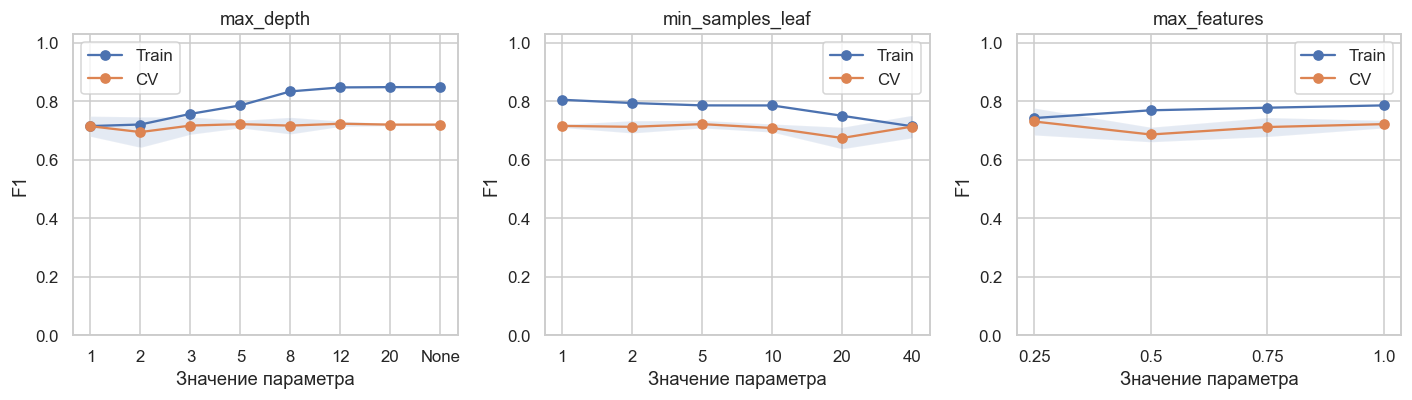

In [5]:
curve_values = {
    'max_depth': [1, 2, 3, 5, 8, 12, 20, None],
    'min_samples_leaf': [1, 2, 5, 10, 20, 40],
    'max_features': [0.25, 0.5, 0.75, 1.0],
}
curves = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (parameter, values) in zip(axes, curve_values.items()):
    train_scores, valid_scores = validation_curve(
        baseline, X_train, y_train, param_name=f'model__{parameter}',
        param_range=values, cv=folds, scoring='f1', n_jobs=1, error_score='raise',
    )
    curves[parameter] = pd.DataFrame({
        'Значение': [str(v) for v in values],
        'Train F1': train_scores.mean(axis=1),
        'CV F1': valid_scores.mean(axis=1),
        'CV std': valid_scores.std(axis=1),
    })
    positions = np.arange(len(values))
    ax.plot(positions, train_scores.mean(axis=1), 'o-', label='Train')
    ax.plot(positions, valid_scores.mean(axis=1), 'o-', label='CV')
    ax.fill_between(positions, valid_scores.mean(axis=1) - valid_scores.std(axis=1),
                    valid_scores.mean(axis=1) + valid_scores.std(axis=1), alpha=0.15)
    ax.set(xticks=positions, xticklabels=[str(v) for v in values],
           title=parameter, xlabel='Значение параметра', ylabel='F1', ylim=(0, 1.03))
    ax.legend()
plt.tight_layout()
plt.show()

При глубине 1 train и CV F1 около 0,715: дерево слишком простое, чтобы описать больше зависимостей. При глубине 5 train F1 растёт до 0,785, CV — до 0,721. У глубоких деревьев train уже около 0,848, а CV остаётся около 0,720: появляется заметный разрыв без выигрыша на проверке.

У min_samples_leaf=5 хороший результат среди проверенных значений этой кривой. При 1 разрыв train/CV больше, а при 40 обе оценки около 0,714 — сильное ограничение мешает обучению. Зависимость не строго монотонная: например, при 20 CV хуже, чем при 40.

Для max_features тоже нет правила «больше — лучше»: в отдельной проверке 0,25 дало CV F1 около 0,730, а 0,5 — 0,686. Результат зависит от других настроек и случайных признаков-кандидатов. Поэтому параметры подбираются вместе. Разумная область на этих данных — умеренная глубина и несколько объектов в листе.

## 6. Устойчивость на разных фолдах

Посмотрю все пять результатов, а не только среднее. Стандартное отклонение показывает разброс между фолдами. Одинаковое среднее может скрывать как ровную работу, так и сильные провалы на отдельных частях.

,Baseline,Grid Search,Random Search
Фолд,,,
1,0.7255,0.7255,0.7706
2,0.7083,0.7083,0.7788
3,0.7447,0.7447,0.7843
4,0.7129,0.7129,0.7037
5,0.7158,0.7158,0.7010


,CV F1,CV std
Baseline,0.7214,0.0129
Grid Search,0.7214,0.0129
Random Search,0.7477,0.0373


Выбрано до проверки test: Random Search


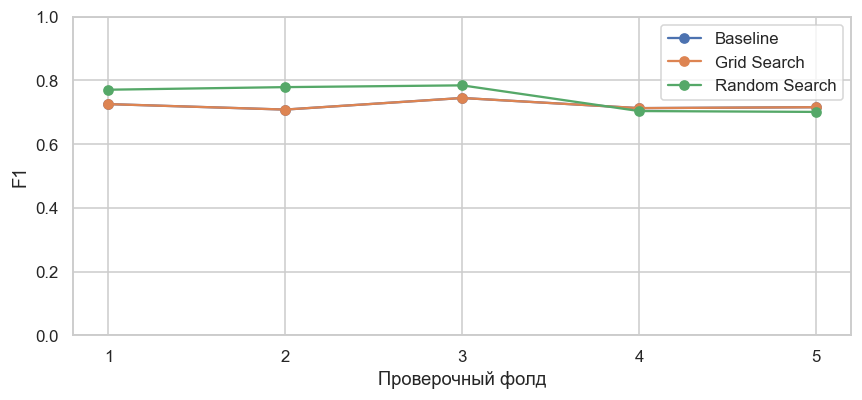

In [6]:
fold_f1 = pd.DataFrame({'Baseline': baseline_scores['test_score']},
                       index=pd.Index(range(1, 6), name='Фолд'))
for name, search in searches.items():
    fold_f1[name] = [search.cv_results_[f'split{i}_test_score'][search.best_index_] for i in range(5)]
stability = pd.DataFrame({'CV F1': fold_f1.mean(), 'CV std': fold_f1.std(ddof=0)})
selected = stability['CV F1'].idxmax()
display(fold_f1.round(4))
display(stability.round(4))
print('Выбрано до проверки test:', selected)
ax = fold_f1.plot(marker='o', figsize=(8, 3.8))
ax.set(ylabel='F1', xlabel='Проверочный фолд', xticks=range(1, 6), ylim=(0, 1))
plt.tight_layout()
plt.show()

У baseline и Grid Search результаты совпали: средний F1 = 0,7214, std = 0,0129. У Random Search среднее выше (0,7477), но разброс тоже больше (0,0373): на первых трёх фолдах F1 около 0,77–0,78, на последних двух — около 0,70. Выбираю его по заранее заданному правилу максимального среднего F1, отмечая меньшую устойчивость.

CV лучших вариантов немного оптимистичен: на тех же фолдах выбирались параметры. Здесь это оценка для выбора, а не независимая оценка всей процедуры поиска.

## 7. Финальная проверка

Подбор завершён. Лучшие варианты уже переобучены поиском на всём train. Исходную модель тоже обучу на всём train и оценю все три решения на одном test. После этой таблицы параметры не меняю.

,CV F1,CV std,Test F1,Accuracy,Precision,Recall
Baseline,0.7214,0.0129,0.6822,0.7709,0.7333,0.6377
Grid Search,0.7214,0.0129,0.6822,0.7709,0.7333,0.6377
Random Search,0.7477,0.0373,0.6822,0.7709,0.7333,0.6377


Выбранный вариант: Random Search; Test F1: 0.6822


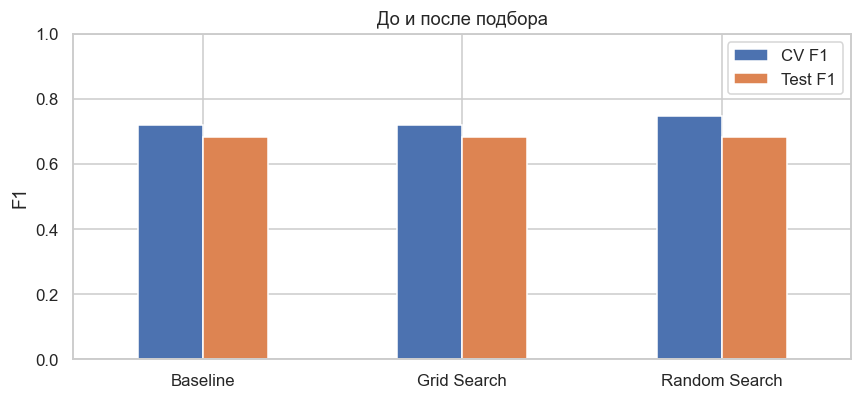

In [7]:
fitted = {'Baseline': clone(baseline).fit(X_train, y_train)}
fitted.update({name: search.best_estimator_ for name, search in searches.items()})
predictions = {name: model.predict(X_test) for name, model in fitted.items()}
results = stability.copy()
for name, prediction in predictions.items():
    results.loc[name, 'Test F1'] = f1_score(y_test, prediction, zero_division=0)
    results.loc[name, 'Accuracy'] = accuracy_score(y_test, prediction)
    results.loc[name, 'Precision'] = precision_score(y_test, prediction, zero_division=0)
    results.loc[name, 'Recall'] = recall_score(y_test, prediction, zero_division=0)
display(results.round(4))
print(f'Выбранный вариант: {selected}; Test F1: {results.loc[selected, "Test F1"]:.4f}')
ax = results[['CV F1', 'Test F1']].plot.bar(rot=0, figsize=(8, 3.8))
ax.set(ylabel='F1', xlabel='', ylim=(0, 1), title='До и после подбора')
plt.tight_layout()
plt.show()

## 8. Вывод

Grid Search не улучшил исходное дерево. Random Search поднял средний CV F1 на 0,0263 (примерно на 3,6% относительно baseline). Но на локальном тесте у всех трёх вариантов F1 = 0,6822: улучшение CV не подтвердилось. Это не одинаковые предсказания — у baseline и Random Search различаются 20 ответов, но итоговые количества ошибок двух классов совпали.

Причины могут быть в небольшом test, чувствительности дерева к составу данных и оптимизме оценки после выбора лучшего из многих вариантов. Подбор улучшает результат на CV, но не гарантирует улучшение на новых объектах. После просмотра test я не меняю параметры и не выбираю другой seed.

Результаты зависят от разбиения, диапазонов поиска и seed. Нового скрытого теста в работе нет. Проверено с Python 3.9, NumPy 1.26.4, pandas 2.3.3, SciPy 1.13.1, scikit-learn 1.6.1, Matplotlib 3.9.4 и seaborn 0.13.2. Ячейки запускать сверху вниз.